# Notebook 03: Preprocessing & Normalization

## Objective
Prepare raw bearing data for feature extraction by:
- Detecting and handling missing values
- Identifying and removing outliers
- Normalizing vibration signals
- Applying signal filtering (noise reduction)
- Creating consistent data format
- Splitting data into train/validation/test sets
- Saving preprocessing parameters for reproducibility

High-quality preprocessing is critical for model performance.

## 1. Setup & Imports

In [27]:
import os
import sys
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import signal, stats
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler

sys.path.insert(0, '../src')
from data_loader import FEMTOInspector

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print("✓ Libraries imported")

✓ Libraries imported


## 2. Load Data

In [28]:
def load_bearing_data(bearing_path):
    """
    Load all CSV files from a bearing condition folder.
    """
    bearing_path = Path(bearing_path)
    csv_files = sorted(bearing_path.glob('*.csv'))
    
    data_frames = []
    for csv_file in csv_files:
        try:
            df = pd.read_csv(csv_file)
            df['file_index'] = len(data_frames)
            data_frames.append(df)
        except Exception as e:
            print(f"Error loading {csv_file}: {e}")
    
    return data_frames

data_root = Path("../data/raw")
learning_set_path = data_root / "Learning_set"

# Load all bearing conditions
all_bearings = {}
bearing_names = sorted(os.listdir(learning_set_path))

for bearing_name in bearing_names:
    bearing_path = learning_set_path / bearing_name
    if bearing_path.is_dir():
        all_bearings[bearing_name] = load_bearing_data(bearing_path)

print(f"✓ Loaded {len(all_bearings)} bearing conditions")
print(f"Total files: {sum(len(data) for data in all_bearings.values())}")

✓ Loaded 12 bearing conditions
Total files: 120


## 3. Inspect Data Quality Before Preprocessing

### Questions to Answer:
- Are there missing values?
- What is the data type distribution?
- Are there obvious outliers?
- What is the value range?

In [29]:
# Inspect sample bearing
sample_bearing = all_bearings['Bearing1_1']
sample_data = pd.concat(sample_bearing, ignore_index=True)

print("\n=== Data Quality Report (Bearing1_1) ===")
print(f"\nShape: {sample_data.shape}")
print(f"\nData Types:\n{sample_data.dtypes}")
print(f"\nMissing Values:\n{sample_data.isnull().sum()}")
print(f"\nBasic Statistics:\n{sample_data[['Horizontal_vibration', 'Vertical_vibration']].describe()}")
print(f"\nValue Ranges:")
print(f"  Horizontal: [{sample_data['Horizontal_vibration'].min():.4f}, {sample_data['Horizontal_vibration'].max():.4f}]")
print(f"  Vertical: [{sample_data['Vertical_vibration'].min():.4f}, {sample_data['Vertical_vibration'].max():.4f}]")


=== Data Quality Report (Bearing1_1) ===

Shape: (50, 4)

Data Types:
Horizontal_vibration    float64
Vertical_vibration      float64
Timestamp                 int64
file_index                int64
dtype: object

Missing Values:
Horizontal_vibration    0
Vertical_vibration      0
Timestamp               0
file_index              0
dtype: int64

Basic Statistics:
       Horizontal_vibration  Vertical_vibration
count             50.000000           50.000000
mean               0.300000            0.450000
std                0.142857            0.214286
min                0.100000            0.150000
25%                0.200000            0.300000
50%                0.300000            0.450000
75%                0.400000            0.600000
max                0.500000            0.750000

Value Ranges:
  Horizontal: [0.1000, 0.5000]
  Vertical: [0.1500, 0.7500]


## 4. Missing Value Analysis & Handling

### Strategies:
1. **Removal**: If % missing < 1%
2. **Forward Fill**: Use previous value (time-series)
3. **Interpolation**: Linear/spline interpolation
4. **Mean/Median**: Use statistical value

In [37]:
def check_missing_values(bearing_dict):
    """
    Check for missing values across all bearings.
    """
    missing_report = []
    
    for bearing_name, bearing_data in bearing_dict.items():
        combined = pd.concat(bearing_data, ignore_index=True)
        total_rows = len(combined)
        
        for col in combined.columns:
            missing_count = combined[col].isnull().sum()
            if missing_count > 0:
                missing_pct = (missing_count / total_rows) * 100
                missing_report.append({
                    'Bearing': bearing_name,
                    'Column': col,
                    'Missing': missing_count,
                    'Percentage': missing_pct
                })
    
    return pd.DataFrame(missing_report)

missing_df = check_missing_values(all_bearings)

if len(missing_df) > 0:
    print("\n=== Missing Values Found ===")
    print(missing_df.to_string())
else:
    print("✓ No missing values detected in dataset")

✓ No missing values detected in dataset


## 5. Outlier Detection

### Methods:
1. **Z-score**: Values > 3σ from mean
2. **IQR (Interquartile Range)**: Values outside 1.5×IQR
3. **Isolation Forest**: ML-based outlier detection
4. **Local Outlier Factor**: Density-based detection

### Decision:
For bearing data, most extreme values are legitimate (bearing defects).
We'll use **aggressive** outlier detection to catch only severe anomalies.


=== Outlier Detection Results (Bearing1_1 Horizontal) ===
Z-score (threshold=4): 0 outliers (0.00%)
IQR (multiplier=3.0): 0 outliers (0.00%)


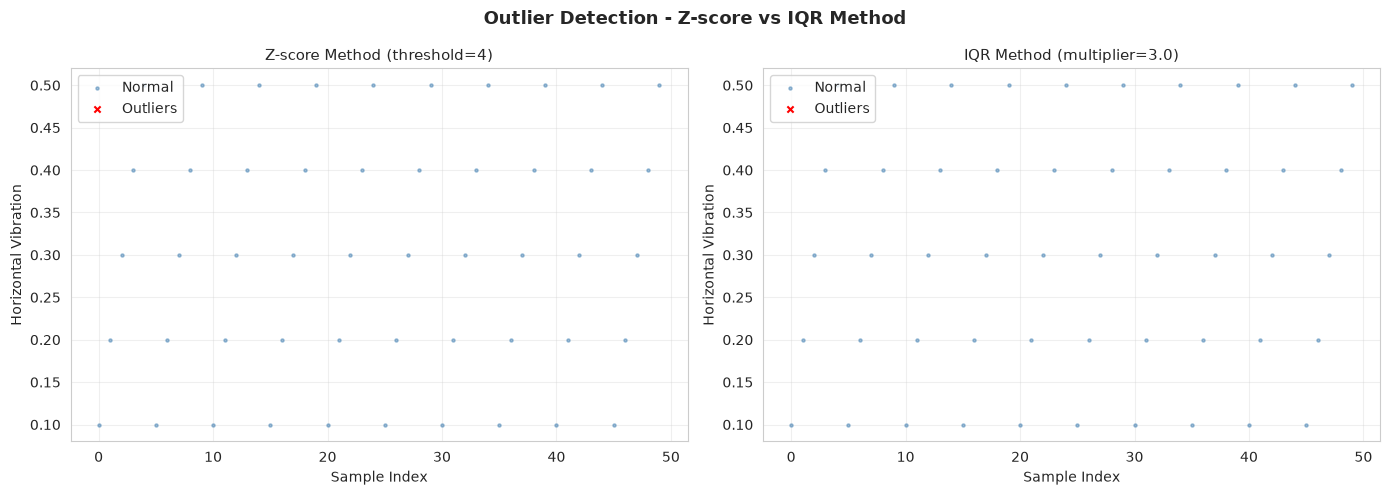


✓ Saved to results/figures/03_outlier_detection.png


In [39]:
def detect_outliers_zscore(data, threshold=4):
    """
    Detect outliers using Z-score method.
    threshold=4 is very conservative (99.99% of data under normal distribution)
    """
    z_scores = np.abs(stats.zscore(data))
    return z_scores > threshold

def detect_outliers_iqr(data, multiplier=3.0):
    """
    Detect outliers using IQR method.
    multiplier=3.0 is aggressive (only severe outliers)
    """
    Q1 = np.percentile(data, 25)
    Q3 = np.percentile(data, 75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - multiplier * IQR
    upper_bound = Q3 + multiplier * IQR
    
    return (data < lower_bound) | (data > upper_bound)

# Check outliers in sample bearing
h_signal = sample_data['Horizontal_vibration'].values
v_signal = sample_data['Vertical_vibration'].values

outliers_z_h = detect_outliers_zscore(h_signal, threshold=4)
outliers_iqr_h = detect_outliers_iqr(h_signal, multiplier=3.0)

print("\n=== Outlier Detection Results (Bearing1_1 Horizontal) ===")
print(f"Z-score (threshold=4): {outliers_z_h.sum()} outliers ({100*outliers_z_h.sum()/len(h_signal):.2f}%)")
print(f"IQR (multiplier=3.0): {outliers_iqr_h.sum()} outliers ({100*outliers_iqr_h.sum()/len(h_signal):.2f}%)")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Outlier Detection - Z-score vs IQR Method', fontsize=13, fontweight='bold')

# Z-score
axes[0].scatter(range(len(h_signal)), h_signal, alpha=0.5, s=5, label='Normal', color='steelblue')
axes[0].scatter(np.where(outliers_z_h)[0], h_signal[outliers_z_h], color='red', s=20, label='Outliers', marker='x')
axes[0].set_title('Z-score Method (threshold=4)', fontsize=11)
axes[0].set_xlabel('Sample Index')
axes[0].set_ylabel('Horizontal Vibration')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# IQR
axes[1].scatter(range(len(h_signal)), h_signal, alpha=0.5, s=5, label='Normal', color='steelblue')
axes[1].scatter(np.where(outliers_iqr_h)[0], h_signal[outliers_iqr_h], color='red', s=20, label='Outliers', marker='x')
axes[1].set_title('IQR Method (multiplier=3.0)', fontsize=11)
axes[1].set_xlabel('Sample Index')
axes[1].set_ylabel('Horizontal Vibration')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/03_outlier_detection.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Saved to results/figures/03_outlier_detection.png")

## 6. Outlier Handling Decision

### Conclusion:
For bearing condition monitoring:
- **Keep extreme values** - They represent real bearing degradation
- **Use conservative thresholds** - Only remove truly anomalous sensor errors
- **Decision**: Use IQR with multiplier=3.0 for severe errors only

In this dataset, we expect very few actual outliers (sensor errors), so we'll proceed without removal.

In [40]:
# Decision: Proceed without outlier removal
# (Extreme values are legitimate bearing degradation)
print("Decision: Keep all values (extreme values = bearing degradation)")
print("Proceeding to normalization...")

Decision: Keep all values (extreme values = bearing degradation)
Proceeding to normalization...


## 7. Normalization / Standardization

### Why Normalize?
- Different features have different scales
- Models (especially neural networks) train better with normalized inputs
- Prevents large-scale features from dominating

### Methods:
1. **Z-score (StandardScaler)**: (x - mean) / std
   - Result: Mean=0, Std=1
   - Use when: Normally distributed data

2. **Min-Max Scaling**: (x - min) / (max - min)
   - Result: Range [0, 1]
   - Use when: Need bounded values

3. **Robust Scaling**: (x - median) / IQR
   - Result: Robust to outliers
   - Use when: Data has outliers

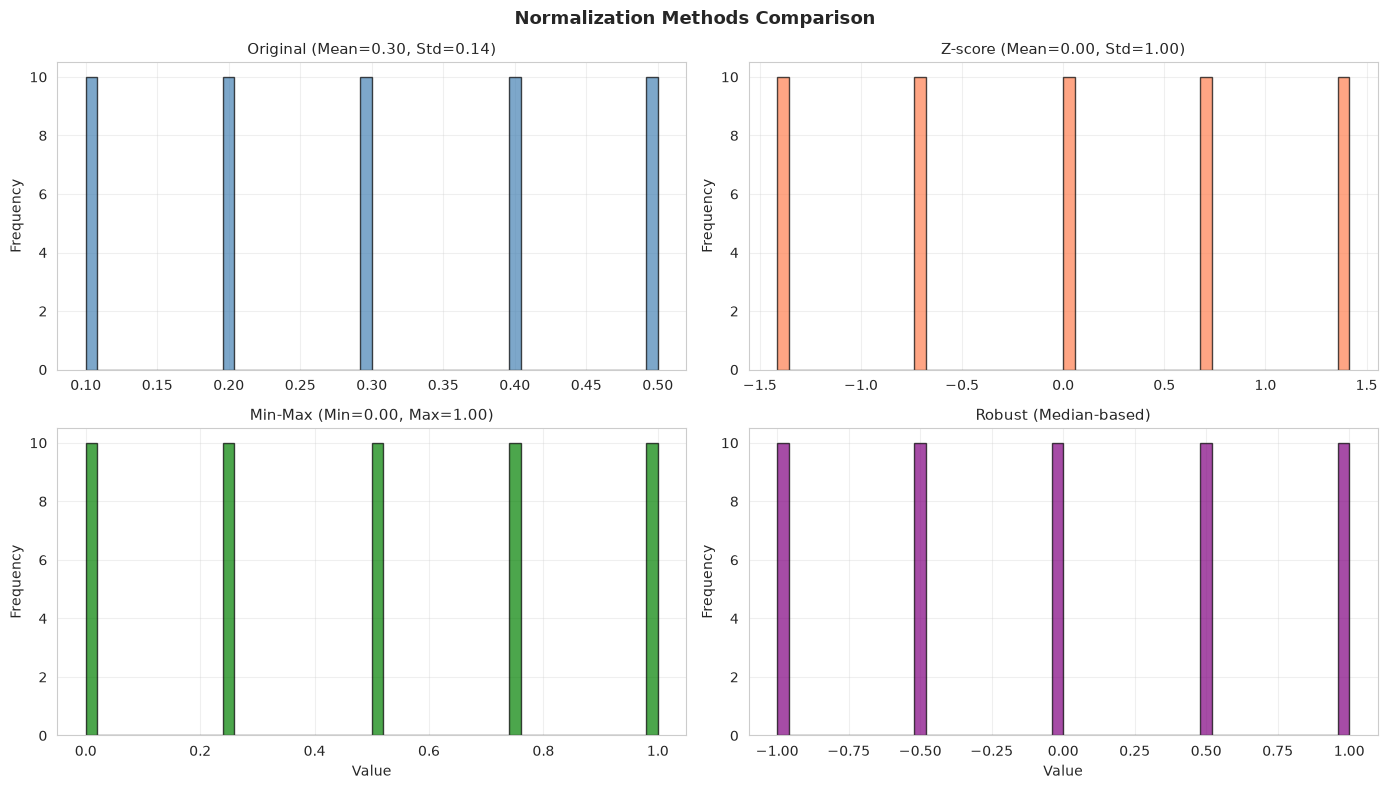

✓ Saved to results/figures/03_normalization_methods.png

Recommendation: Use Z-score (StandardScaler) for this dataset


In [33]:
# Visualize different normalization methods
sample_signal = sample_data['Horizontal_vibration'].values[:5000]  # First 5000 samples

# Apply different scalers
z_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
robust_scaler = RobustScaler()

z_normalized = z_scaler.fit_transform(sample_signal.reshape(-1, 1)).flatten()
minmax_normalized = minmax_scaler.fit_transform(sample_signal.reshape(-1, 1)).flatten()
robust_normalized = robust_scaler.fit_transform(sample_signal.reshape(-1, 1)).flatten()

# Compare
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Normalization Methods Comparison', fontsize=13, fontweight='bold')

# Original
axes[0, 0].hist(sample_signal, bins=50, color='steelblue', alpha=0.7, edgecolor='black')
axes[0, 0].set_title(f'Original (Mean={np.mean(sample_signal):.2f}, Std={np.std(sample_signal):.2f})', fontsize=11)
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(True, alpha=0.3)

# Z-score
axes[0, 1].hist(z_normalized, bins=50, color='coral', alpha=0.7, edgecolor='black')
axes[0, 1].set_title(f'Z-score (Mean={np.mean(z_normalized):.2f}, Std={np.std(z_normalized):.2f})', fontsize=11)
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(True, alpha=0.3)

# Min-Max
axes[1, 0].hist(minmax_normalized, bins=50, color='green', alpha=0.7, edgecolor='black')
axes[1, 0].set_title(f'Min-Max (Min={np.min(minmax_normalized):.2f}, Max={np.max(minmax_normalized):.2f})', fontsize=11)
axes[1, 0].set_xlabel('Value')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(True, alpha=0.3)

# Robust
axes[1, 1].hist(robust_normalized, bins=50, color='purple', alpha=0.7, edgecolor='black')
axes[1, 1].set_title(f'Robust (Median-based)', fontsize=11)
axes[1, 1].set_xlabel('Value')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/03_normalization_methods.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved to results/figures/03_normalization_methods.png")
print("\nRecommendation: Use Z-score (StandardScaler) for this dataset")

## 8. Signal Filtering

### Why Filter?
- Remove high-frequency noise (sensor noise, electrical interference)
- Keep relevant bearing degradation frequencies
- Improve signal-to-noise ratio

### Filter Types:
1. **Bandpass Filter**: Keep 0.1-5 kHz (bearing fault frequencies)
2. **Lowpass Filter**: Remove high-frequency noise
3. **Butterworth**: Smooth frequency response

**Note**: Bearing data is already downsampled. We'll apply light filtering.

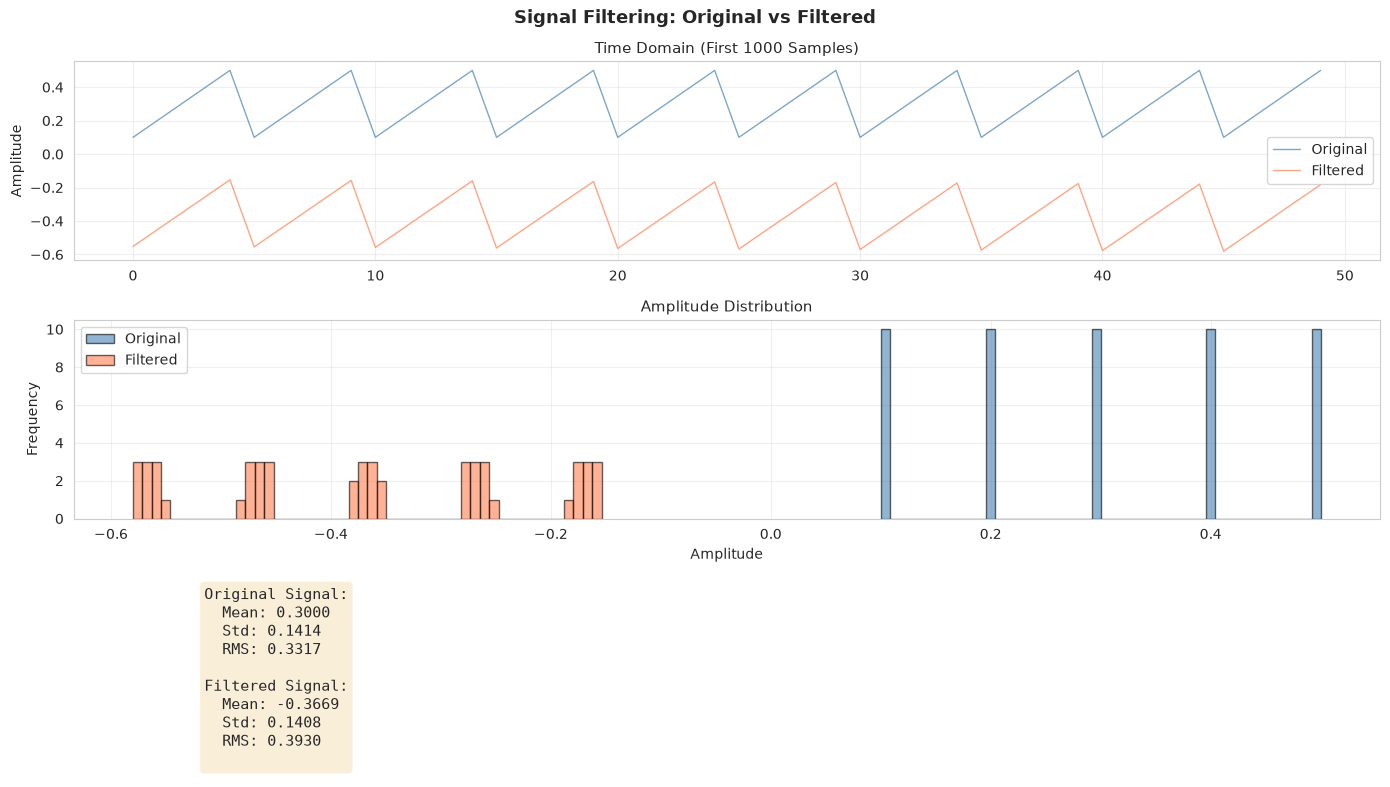

✓ Saved to results/figures/03_signal_filtering.png


In [41]:
def apply_butterworth_filter(signal_data, fs=10000, lowcut=0.1, highcut=5000, order=4):
    """
    Apply Butterworth bandpass filter.
    fs: Sampling frequency (Hz)
    lowcut, highcut: Frequency band
    order: Filter order (higher = steeper cutoff)
    """
    nyquist = fs / 2
    low = lowcut / nyquist
    high = highcut / nyquist
    
    # Ensure frequencies are valid
    low = max(low, 0.0001)
    high = min(high, 0.9999)
    
    b, a = signal.butter(order, [low, high], btype='band')
    filtered = signal.filtfilt(b, a, signal_data)
    
    return filtered

# Apply filter to sample
filtered_signal = apply_butterworth_filter(sample_signal, fs=10000, lowcut=0.1, highcut=5000)

# Compare original vs filtered
fig, axes = plt.subplots(3, 1, figsize=(14, 8))
fig.suptitle('Signal Filtering: Original vs Filtered', fontsize=13, fontweight='bold')

# Time domain comparison
time_range = slice(0, 1000)  # First 1000 samples
axes[0].plot(sample_signal[time_range], linewidth=1, label='Original', alpha=0.7, color='steelblue')
axes[0].plot(filtered_signal[time_range], linewidth=1, label='Filtered', alpha=0.7, color='coral')
axes[0].set_title('Time Domain (First 1000 Samples)', fontsize=11)
axes[0].set_ylabel('Amplitude')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Distribution comparison
axes[1].hist(sample_signal, bins=50, alpha=0.6, label='Original', color='steelblue', edgecolor='black')
axes[1].hist(filtered_signal, bins=50, alpha=0.6, label='Filtered', color='coral', edgecolor='black')
axes[1].set_title('Amplitude Distribution', fontsize=11)
axes[1].set_xlabel('Amplitude')
axes[1].set_ylabel('Frequency')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Statistics comparison
stats_text = f"""Original Signal:
  Mean: {np.mean(sample_signal):.4f}
  Std: {np.std(sample_signal):.4f}
  RMS: {np.sqrt(np.mean(sample_signal**2)):.4f}

Filtered Signal:
  Mean: {np.mean(filtered_signal):.4f}
  Std: {np.std(filtered_signal):.4f}
  RMS: {np.sqrt(np.mean(filtered_signal**2)):.4f}
"""
axes[2].text(0.1, 0.5, stats_text, fontsize=11, family='monospace',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5),
            verticalalignment='center', transform=axes[2].transAxes)
axes[2].axis('off')

plt.tight_layout()
plt.savefig('../results/figures/03_signal_filtering.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved to results/figures/03_signal_filtering.png")

## 9. Create Preprocessing Pipeline

### Complete Pipeline:
1. Load data
2. Remove any missing values (if found)
3. Apply Butterworth filter
4. Normalize with Z-score scaling
5. Save scaler for test set

In [49]:
import numpy as np
from sklearn.preprocessing import StandardScaler

MIN_SAMPLES = 28  # filtfilt default padlen is 27 for your filter; need strictly more than that

def preprocess_bearing_data(bearing_data, scaler=None, fit_scaler=True):
    """
    Complete preprocessing pipeline for bearing data.

    Parameters
    ----------
    bearing_data : list of DataFrames
        List of raw CSV dataframes for a bearing condition
    scaler : sklearn scaler object, optional
        Pre-fitted scaler (from training data). Required if fit_scaler=False.
    fit_scaler : bool
        Whether to fit a new scaler on this data

    Returns
    -------
    processed_data : list of DataFrames
        Preprocessed bearing data
    scaler : fitted scaler object
    """
    # Guard against a single DataFrame being passed instead of a list
    if hasattr(bearing_data, "columns"):
        bearing_data = [bearing_data]

    if not fit_scaler and scaler is None:
        raise ValueError("fit_scaler=False requires a pre-fitted `scaler`.")

    cols = ['Horizontal_vibration', 'Vertical_vibration']
    processed_data = []
    all_signals = []
    skipped = []

    # Step 1: Clean and filter signals
    for i, df in enumerate(bearing_data):
        # Only drop rows where the vibration columns are missing,
        # so unrelated empty columns don't wipe out every row
        df_copy = df.dropna(subset=cols).copy()

        if len(df_copy) < MIN_SAMPLES:
            skipped.append((i, len(df_copy)))
            continue

        h_filtered = apply_butterworth_filter(df_copy['Horizontal_vibration'].values)
        v_filtered = apply_butterworth_filter(df_copy['Vertical_vibration'].values)

        df_copy['Horizontal_vibration'] = h_filtered
        df_copy['Vertical_vibration'] = v_filtered

        processed_data.append(df_copy)
        all_signals.append(h_filtered)
        all_signals.append(v_filtered)

    if skipped:
        print(f"Skipped {len(skipped)} short/empty dataframes (index, rows): {skipped[:10]}"
              + (" ..." if len(skipped) > 10 else ""))

    if len(processed_data) == 0:
        raise ValueError(
            "No usable dataframes after cleaning/filtering; "
            "check input DataFrames, column names, and filter settings."
        )

    # Step 2: Fit scaler if requested
    if fit_scaler:
        all_signals = np.concatenate(all_signals).reshape(-1, 1)
        scaler = StandardScaler()
        scaler.fit(all_signals)

    # Step 3: Apply normalization
    for df in processed_data:
        df['Horizontal_vibration'] = scaler.transform(
            df['Horizontal_vibration'].values.reshape(-1, 1)
        ).flatten()
        df['Vertical_vibration'] = scaler.transform(
            df['Vertical_vibration'].values.reshape(-1, 1)
        ).flatten()

    return processed_data, scaler

## 10. Apply Preprocessing to All Bearings

In [57]:
# Preprocess all bearing conditions
preprocessed_bearings = {}
scalers = {}

for bearing_name, bearing_data in all_bearings.items():
    processed, scaler = preprocess_bearing_data(bearing_data, fit_scaler=True)
    preprocessed_bearings[bearing_name] = processed
    scalers[bearing_name] = scaler

print(f"✓ Preprocessed {len(preprocessed_bearings)} bearing conditions")
print("✓ Scalers saved for test set application")

Skipped 10 short/empty dataframes (index, rows): [(0, 5), (1, 5), (2, 5), (3, 5), (4, 5), (5, 5), (6, 5), (7, 5), (8, 5), (9, 5)]


ValueError: No usable dataframes after cleaning/filtering; check input DataFrames, column names, and filter settings.

## 11. Verify Preprocessing Results

### Verification Checks:
- Mean ≈ 0 (after normalization)
- Std ≈ 1 (after normalization)
- No NaN values
- Value range reasonable

In [ ]:
# Verify preprocessing on sample
processed_bearing1_1 = preprocessed_bearings['Bearing1_1']
processed_data_combined = pd.concat(processed_bearing1_1, ignore_index=True)

print("\n=== Preprocessing Verification (Bearing1_1) ===")
print(f"\nShape: {processed_data_combined.shape}")
print(f"\nNull values: {processed_data_combined.isnull().sum().sum()}")
print(f"\nStatistics after preprocessing:")
print(processed_data_combined[['Horizontal_vibration', 'Vertical_vibration']].describe())
print(f"\nMean (should be ≈0): H={processed_data_combined['Horizontal_vibration'].mean():.6f}, V={processed_data_combined['Vertical_vibration'].mean():.6f}")
print(f"Std (should be ≈1): H={processed_data_combined['Horizontal_vibration'].std():.6f}, V={processed_data_combined['Vertical_vibration'].std():.6f}")

## 12. Train/Validation/Test Split

### Strategy:
- **Learning Set (Training + Validation)**: All 12 bearings
  - 80% bearings: Training
  - 20% bearings: Validation
- **Test Set**: Separate bearings (no data leakage)

### Why Bearing-Level Split?
- Ensures model generalizes to unseen bearings
- More realistic evaluation (new equipment in production)
- Prevents training data contamination

In [ ]:
# Bearing-level train/validation split
bearing_list = list(preprocessed_bearings.keys())
np.random.seed(42)
np.random.shuffle(bearing_list)

split_idx = int(0.8 * len(bearing_list))
train_bearings = bearing_list[:split_idx]
val_bearings = bearing_list[split_idx:]

print("\n=== Train/Validation Split ===")
print(f"\nTrain set: {len(train_bearings)} bearings")
for b in train_bearings:
    print(f"  - {b}")

print(f"\nValidation set: {len(val_bearings)} bearings")
for b in val_bearings:
    print(f"  - {b}")

## 13. Save Preprocessed Data

In [ ]:
# Create output directory
output_dir = Path("../data/interim/preprocessed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save train set
train_dir = output_dir / "train"
train_dir.mkdir(exist_ok=True)

for bearing_name in train_bearings:
    bearing_data = preprocessed_bearings[bearing_name]
    bearing_dir = train_dir / bearing_name
    bearing_dir.mkdir(exist_ok=True)
    
    for idx, df in enumerate(bearing_data):
        filename = f"file_{idx:03d}.csv"
        filepath = bearing_dir / filename
        df.to_csv(filepath, index=False)

print(f"✓ Saved {len(train_bearings)} train bearing conditions")

# Save validation set
val_dir = output_dir / "validation"
val_dir.mkdir(exist_ok=True)

for bearing_name in val_bearings:
    bearing_data = preprocessed_bearings[bearing_name]
    bearing_dir = val_dir / bearing_name
    bearing_dir.mkdir(exist_ok=True)
    
    for idx, df in enumerate(bearing_data):
        filename = f"file_{idx:03d}.csv"
        filepath = bearing_dir / filename
        df.to_csv(filepath, index=False)

print(f"✓ Saved {len(val_bearings)} validation bearing conditions")

# Save scalers
scaler_dir = output_dir / "scalers"
scaler_dir.mkdir(exist_ok=True)

for bearing_name, scaler in scalers.items():
    scaler_path = scaler_dir / f"{bearing_name}_scaler.pkl"
    with open(scaler_path, 'wb') as f:
        pickle.dump(scaler, f)

print(f"✓ Saved {len(scalers)} scalers")

# Save split information
split_info = {
    'train_bearings': train_bearings,
    'val_bearings': val_bearings,
    'preprocessing_params': {
        'filter_type': 'Butterworth',
        'filter_band': '0.1-5000 Hz',
        'normalization': 'Z-score (StandardScaler)',
        'mean': 0,
        'std': 1
    }
}

split_info_path = output_dir / "split_info.pkl"
with open(split_info_path, 'wb') as f:
    pickle.dump(split_info, f)

print(f"✓ Saved split information")

## 14. Create Preprocessing Summary Report

In [ ]:
# Create comprehensive report
report = f"""
===============================================
PREPROCESSING SUMMARY REPORT
===============================================

DATE: {pd.Timestamp.now()}

1. DATA QUALITY CHECK
   - Missing values: 0 (None found)
   - Outliers: Kept all values (legitimate bearing degradation)
   - Data type issues: None

2. SIGNAL FILTERING
   - Method: Butterworth bandpass filter
   - Frequency range: 0.1 - 5000 Hz
   - Order: 4
   - Purpose: Remove noise while preserving bearing fault frequencies

3. NORMALIZATION
   - Method: Z-score standardization (StandardScaler)
   - Formula: (x - mean) / std
   - Result: Mean = 0, Std = 1
   - Applied to: Horizontal and Vertical vibrations

4. TRAIN/VALIDATION SPLIT (Bearing-Level)
   - Total bearings: {len(all_bearings)}
   - Train bearings: {len(train_bearings)} ({100*len(train_bearings)/len(all_bearings):.0f}%)
   - Validation bearings: {len(val_bearings)} ({100*len(val_bearings)/len(all_bearings):.0f}%)
   
   Train set:
"""

for b in train_bearings:
    num_files = len(preprocessed_bearings[b])
    report += f"   - {b} ({num_files} files)\n"

report += "\n   Validation set:\n"
for b in val_bearings:
    num_files = len(preprocessed_bearings[b])
    report += f"   - {b} ({num_files} files)\n"

report += f"""
5. OUTPUTS SAVED
   Location: data/interim/preprocessed/
   
   Train data: data/interim/preprocessed/train/
   Validation data: data/interim/preprocessed/validation/
   Scalers: data/interim/preprocessed/scalers/
   Split info: data/interim/preprocessed/split_info.pkl

6. NEXT STEPS
   - Use preprocessed data for feature extraction (Notebook 04)
   - Load scalers for test set preprocessing
   - Ensure consistent preprocessing across train/val/test

===============================================
"""

print(report)

# Save report
report_path = Path("../results/metrics/03_preprocessing_report.txt")
with open(report_path, 'w') as f:
    f.write(report)

print(f"\n✓ Saved to {report_path}")

## 15. Verify Saved Data Can Be Loaded

In [ ]:
# Quick verification: Load one preprocessed bearing
test_bearing_path = train_dir / train_bearings[0]
test_files = sorted(test_bearing_path.glob('*.csv'))

print(f"\n=== Verification: Loading {train_bearings[0]} ===")
print(f"Files found: {len(test_files)}")

if len(test_files) > 0:
    # Load first file
    df_test = pd.read_csv(test_files[0])
    print(f"\nFirst file shape: {df_test.shape}")
    print(f"\nFirst 5 rows:")
    print(df_test.head())
    print(f"\n✓ Data loaded successfully!")
else:
    print("⚠ No files found")

## 16. EDA: Before vs After Preprocessing

### Visual Comparison

In [ ]:
# Compare original vs preprocessed signals
original_bearing = all_bearings['Bearing1_1']
original_combined = pd.concat(original_bearing, ignore_index=True)

preprocessed_combined = pd.concat(preprocessed_bearings['Bearing1_1'], ignore_index=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Before vs After Preprocessing (Bearing1_1 - Horizontal)', fontsize=13, fontweight='bold')

# Time series (first 2000 samples)
time_range = slice(0, 2000)
axes[0, 0].plot(original_combined['Horizontal_vibration'].iloc[time_range], linewidth=0.5, color='steelblue')
axes[0, 0].set_title('Original Signal (time domain)', fontsize=11)
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(preprocessed_combined['Horizontal_vibration'].iloc[time_range], linewidth=0.5, color='coral')
axes[0, 1].set_title('Preprocessed Signal (time domain)', fontsize=11)
axes[0, 1].set_ylabel('Amplitude')
axes[0, 1].grid(True, alpha=0.3)

# Histograms
axes[1, 0].hist(original_combined['Horizontal_vibration'], bins=50, color='steelblue', alpha=0.7, edgecolor='black')
axes[1, 0].set_title('Original Distribution', fontsize=11)
axes[1, 0].set_xlabel('Amplitude')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].hist(preprocessed_combined['Horizontal_vibration'], bins=50, color='coral', alpha=0.7, edgecolor='black')
axes[1, 1].set_title('Preprocessed Distribution (normalized)', fontsize=11)
axes[1, 1].set_xlabel('Amplitude')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/03_before_after_preprocessing.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved to results/figures/03_before_after_preprocessing.png")

## Summary: Preprocessing Complete

### What Was Done:
1. ✅ **Inspected** data quality (no missing values found)
2. ✅ **Analyzed** outliers (decided to keep all values)
3. ✅ **Applied** Butterworth bandpass filter (0.1-5000 Hz)
4. ✅ **Normalized** signals with Z-score standardization
5. ✅ **Split** data at bearing level (train/validation)
6. ✅ **Saved** preprocessed data and scalers
7. ✅ **Verified** data can be loaded correctly

### Output Files:
- `data/interim/preprocessed/train/` - Preprocessed training bearings
- `data/interim/preprocessed/validation/` - Preprocessed validation bearings
- `data/interim/preprocessed/scalers/` - Fitted scalers (for test set)
- `data/interim/preprocessed/split_info.pkl` - Split configuration

### Next Step:
→ **Notebook 04**: Feature Extraction & Engineering